# Example 24: Correcting the site attenuation

The site attenuation, $\kappa$, is the slope of the log of the Fourier amplitudes against frequency, $a(f) \propto \exp(-\pi \kappa f)$, over a range of frequencies (Anderson and Hough, 1984). A site response calculation gives the motion at the surface a $\kappa$ that follows from the input motion, the damping and the scattering of the profile, which may not be the $\kappa$ that is expected at the site.

`KappaCorrectedCalculator` wraps a calculator. It reads the $\kappa$ of the input motion, lets the wrapped calculation run, and corrects the transfer function of each location by $\exp(\pi (\kappa_{fit} - \kappa_{target}) f)$ so that the motion has the target $\kappa$. Because the outputs take their transfer function from the calculator, every output is corrected without changes to it.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pygmm
from pygmm.fourier_spectrum import SourceTheoryModel

from pystrata import motion, output, propagation, site

%matplotlib inline

## Profile and motion

Three layers of Darendeli soil over rock, and a random vibration theory input motion from a source-theory model for a $M_w$ 6.5 earthquake 20 km away.

In [2]:
def darendeli(**kw):
    return site.SoilType.from_curves(pygmm.DarendeliSoilType(**kw).curves())


profile = site.Profile(
    [
        site.Layer(
            darendeli(unit_wt=18.0, plas_index=0, ocr=1, stress_mean=200),
            thickness,
            shear_vel,
        )
        for thickness, shear_vel in [(10, 300), (10, 400), (20, 600)]
    ]
    + [site.Layer(site.SoilType("Rock", 24.0, None, 0.01), 0, 1200)]
)
rvt = motion.RvtMotion.from_fas(SourceTheoryModel(6.5, 20, "wna"))
loc_in = profile.location("outcrop", index=-1)
loc_out = output.OutputLocation("outcrop", index=0)
surface = profile.location("outcrop", index=0)

## Attenuation of the motions

The fit is over 10 to 30 Hz. The wrapper reports the attenuation of the input motion (`initial_kappa`) and, with `calc_kappa`, that of the motion at a location before the correction.

In [3]:
FIT = (10.0, 30.0)

calc = propagation.KappaCorrectedCalculator(
    propagation.EquivalentLinearCalculator(),
    kappa_target=0.04,
    min_freq=FIT[0],
    max_freq=FIT[1],
)
calc(rvt, profile, loc_in)

print(f"Input motion:                  kappa = {calc.initial_kappa:.4f} s")
print(f"Surface, before the correction: kappa = {calc.calc_kappa(surface):.4f} s")
print(f"Target:                        kappa = {calc.kappa_target:.4f} s")

Input motion:                  kappa = 0.0417 s
Surface, before the correction: kappa = 0.0507 s
Target:                        kappa = 0.0400 s


## Fourier spectrum at the surface

The spectrum with the targets of 0.02, 0.04 and 0.06 s, and the uncorrected spectrum from the same calculation.

target None: kappa of the output = 0.0507 s
target 0.02: kappa of the output = 0.0200 s
target 0.04: kappa of the output = 0.0400 s
target 0.06: kappa of the output = 0.0600 s


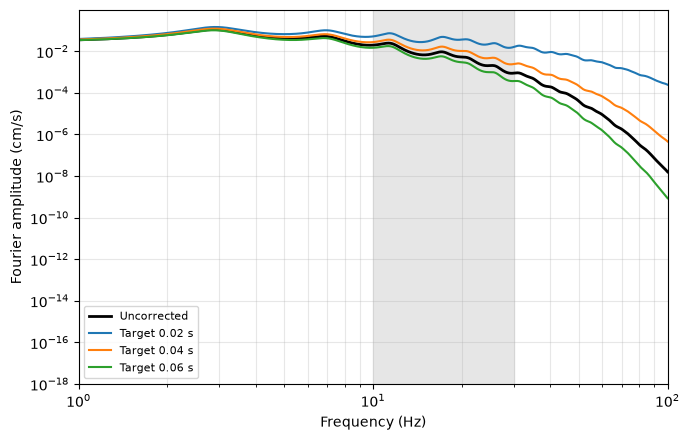

In [4]:
freqs = rvt.freqs


def surface_fas(target):
    """Fourier spectrum at the surface; uncorrected if the target is None."""
    inner = propagation.EquivalentLinearCalculator()
    c = (
        inner
        if target is None
        else propagation.KappaCorrectedCalculator(inner, target, *FIT)
    )
    out = output.FourierAmplitudeSpectrumOutput(freqs, loc_out)
    c(rvt, profile, loc_in)
    out(c)
    return np.asarray(out.values)


fig, ax = plt.subplots(figsize=(7, 4.5))
spectra = {None: surface_fas(None)} | {t: surface_fas(t) for t in (0.02, 0.04, 0.06)}
ax.plot(freqs, spectra[None], "k", lw=2, label="Uncorrected")
for target in (0.02, 0.04, 0.06):
    ax.plot(freqs, spectra[target], label=f"Target {target} s")
ax.axvspan(*FIT, color="0.9", zorder=0)
ax.set(
    xscale="log",
    yscale="log",
    xlim=(1, 100),
    xlabel="Frequency (Hz)",
    ylabel="Fourier amplitude (cm/s)",
)
ax.grid(True, which="both", alpha=0.3)
ax.legend(fontsize=8)
fig.tight_layout()

for target, spec in spectra.items():
    kappa = motion.fit_attenuation(freqs, spec, *FIT)[0]
    print(f"target {target}: kappa of the output = {kappa:.4f} s")

## Response spectrum

The correction changes the high-frequency response. Any output takes the corrected transfer function from the calculator, here the response spectrum.

{0.02: 1.99, 0.04: 1.2, 0.06: 0.87}


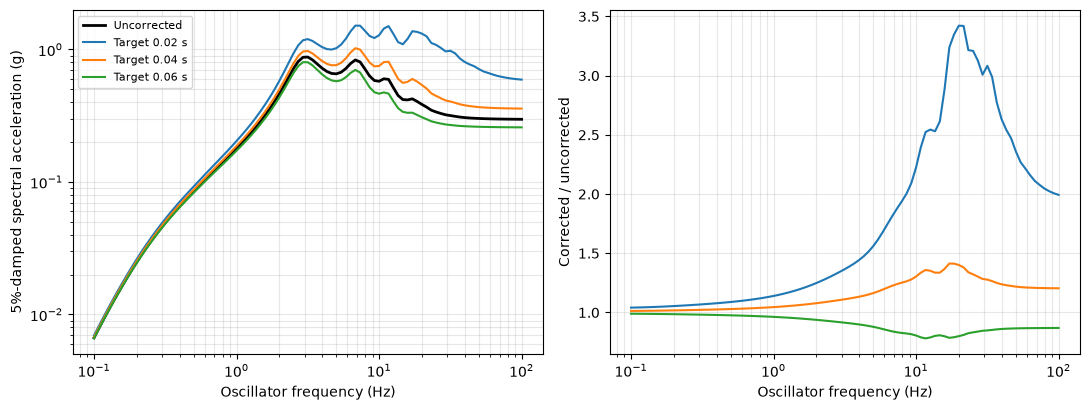

In [5]:
osc_freqs = np.geomspace(0.1, 100, 91)


def surface_spectrum(target):
    inner = propagation.EquivalentLinearCalculator()
    c = (
        inner
        if target is None
        else propagation.KappaCorrectedCalculator(inner, target, *FIT)
    )
    out = output.ResponseSpectrumOutput(osc_freqs, loc_out, 0.05)
    c(rvt, profile, loc_in)
    out(c)
    return np.asarray(out.values)


resp = {None: surface_spectrum(None)} | {
    t: surface_spectrum(t) for t in (0.02, 0.04, 0.06)
}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharex=True)
axes[0].plot(osc_freqs, resp[None], "k", lw=2, label="Uncorrected")
for target in (0.02, 0.04, 0.06):
    axes[0].plot(osc_freqs, resp[target], label=f"Target {target} s")
    axes[1].plot(osc_freqs, resp[target] / resp[None], label=f"Target {target} s")
axes[0].set(xscale="log", yscale="log", ylabel="5%-damped spectral acceleration (g)")
axes[1].set(xscale="log", ylabel="Corrected / uncorrected")
for ax in axes:
    ax.set_xlabel("Oscillator frequency (Hz)")
    ax.grid(True, which="both", alpha=0.3)
axes[0].legend(fontsize=8)
fig.tight_layout()
print({t: round(float(resp[t][-1] / resp[None][-1]), 2) for t in (0.02, 0.04, 0.06)})

## Time series

The same wrapper corrects the time series at the surface for a recorded motion.

Input motion: kappa = 0.0725 s, PGA = 0.503 g


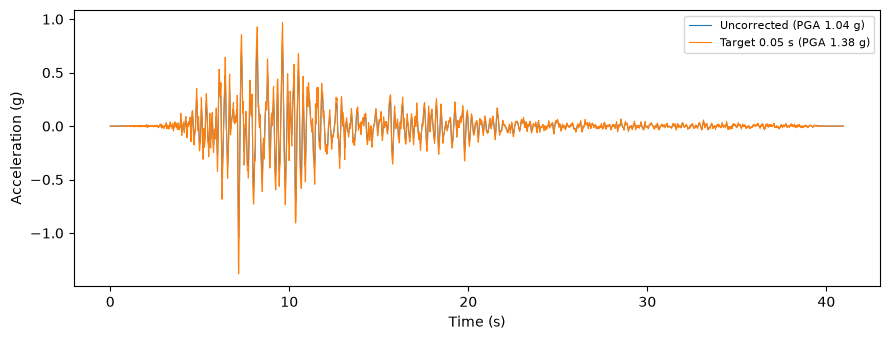

In [6]:
ts = motion.TimeSeriesMotion.load_at2_file("data/NIS090.AT2")

times = {}
for name, target in [("Uncorrected", None), ("Target 0.05 s", 0.05)]:
    inner = propagation.LinearElasticCalculator()
    c = (
        inner
        if target is None
        else propagation.KappaCorrectedCalculator(inner, target, *FIT)
    )
    out = output.AccelerationTSOutput(loc_out)
    c(ts, profile, loc_in)
    out(c)
    times[name] = (out.refs, np.asarray(out.values))

print(
    f"Input motion: kappa = {ts.calc_attenuation(*FIT)[0]:.4f} s, PGA = {np.abs(ts.accels).max():.3f} g"
)
fig, ax = plt.subplots(figsize=(9, 3.5))
for name, (t, a) in times.items():
    ax.plot(t, a, lw=0.8, label=f"{name} (PGA {np.abs(a).max():.2f} g)")
ax.set(xlabel="Time (s)", ylabel="Acceleration (g)")
ax.legend(fontsize=8)
fig.tight_layout()

### Observations

- **The site changes the attenuation of the input motion.** The input motion has a $\\kappa$ of 0.042 s and the motion at the surface of the profile has 0.051 s before the correction, so the profile adds 0.009 s.
- **The corrected motion has the target** over the fit range (0.020, 0.040 and 0.060 s for the three targets), because the correction is a factor of $\\exp(\\pi \\Delta\\kappa f)$ and the fit is log-linear. A target that is less than the uncorrected $\\kappa$ increases the high frequencies and a larger one decreases them.
- **The response spectrum changes mostly at high frequencies**: at 100 Hz the spectral acceleration is 2.0, 1.2 and 0.87 times the uncorrected value for the targets of 0.02, 0.04 and 0.06 s, and below 1 Hz it changes by at most 14%, 4.5% and 4%.
- **The time series is corrected as well**: with a target of 0.05 s, below the 0.072 s of the recorded input, the PGA at the surface is 1.38 g rather than 1.04 g. The wrapper works with the other calculators, including the dam calculators, and with `run_ensemble`.